# 🌍 Cluster Analysis – Global Development Dataset

**Business objective:** group the countries of the world into clusters using economic and development indicators, compare different clustering models, and deploy the result as a Streamlit app.

**What is clustering?** It is *unsupervised learning*: there is no "right answer" column. The computer looks at the numbers and puts **similar countries in the same group**.

**Steps in this notebook** (matching the project milestones)

| Week | Milestone | Sections |
|---|---|---|
| 1 | EDA | 1 – 7 |
| 2 | Model building & evaluation | 8 – 13 |
| 3 | Deployment | 14 – 15 |
| 4 | Final presentation | 16 (conclusion) 

In [57]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

import warnings
warnings.filterwarnings("ignore")

## 2. Load the data


In [58]:
df=pd.read_excel('World_development_mesurement.xlsx')
df.head()

,Birth Rate,Business Tax Rate,CO2 Emissions,Country,Days to Start Business,Ease of Business,Energy Usage,GDP,Health Exp % GDP,Health Exp/Capita,...,Life Expectancy Male,Mobile Phone Usage,Number of Records,Population 0-14,Population 15-64,Population 65+,Population Total,Population Urban,Tourism Inbound,Tourism Outbound
0,0.020,NaN,87931.0,Algeria,NaN,NaN,26998.0,"$54,790,058,957",0.035,$60,...,67.0,0.0,1,0.342,0.619,0.039,31719449,0.599,"$102,000,000","$193,000,000"
1,0.050,NaN,9542.0,Angola,NaN,NaN,7499.0,"$9,129,594,819",0.034,$22,...,44.0,0.0,1,0.476,0.499,0.025,13924930,0.324,"$34,000,000","$146,000,000"
2,0.043,NaN,1617.0,Benin,NaN,NaN,1983.0,"$2,359,122,303",0.043,$15,...,53.0,0.0,1,0.454,0.517,0.029,6949366,0.383,"$77,000,000","$50,000,000"
3,0.027,NaN,4276.0,Botswana,NaN,NaN,1836.0,"$5,788,311,645",0.047,$152,...,49.0,0.1,1,0.383,0.587,0.029,1755375,0.532,"$227,000,000","$209,000,000"
4,0.046,NaN,1041.0,Burkina Faso,NaN,NaN,NaN,"$2,610,959,139",0.051,$12,...,49.0,0.0,1,0.468,0.505,0.028,11607944,0.178,"$23,000,000","$30,000,000"


## 3. Understand the data
**Explanation:** before changing anything we check the data types, duplicates and how many countries there are.

In [59]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2704 entries, 0 to 2703
Data columns (total 25 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Birth Rate              2585 non-null   float64
 1   Business Tax Rate       1423 non-null   object 
 2   CO2 Emissions           2125 non-null   float64
 3   Country                 2704 non-null   object 
 4   Days to Start Business  1718 non-null   float64
 5   Ease of Business        185 non-null    float64
 6   Energy Usage            1785 non-null   float64
 7   GDP                     2494 non-null   object 
 8   Health Exp % GDP        2395 non-null   float64
 9   Health Exp/Capita       2395 non-null   object 
 10  Hours to do Tax         1416 non-null   float64
 11  Infant Mortality Rate   2444 non-null   float64
 12  Internet Usage          2531 non-null   float64
 13  Lending Interest        1880 non-null   float64
 14  Life Expectancy Female  2568 non-null   

In [60]:
print("Duplicate rows:", df.duplicated().sum())
print("Number of different countries:", df["Country"].nunique())
print("Rows for each country:", df["Country"].value_counts().unique())

Duplicate rows: 0
Number of different countries: 208
Rows for each country: [13]


**Conclusion – 3 important findings**
1. `GDP`, `Health Exp/Capita`, `Tourism Inbound`, `Tourism Outbound` and `Business Tax Rate` are **text** (like `$54,790,058,957` and `76.9%`) – we must convert them to numbers.
2. There are only **208 countries** and each one appears **13 times** (13 years). So the data is *country × year*.
3. `Number of Records` is always 1, so it is useless.

## 4. Data cleaning
**Explanation:** machine-learning models can only use numbers. We remove the symbols `$`, `,` and `%` and convert the text to numbers. A percentage like `76.9%` becomes `0.769`, the same style as the other columns.

In [61]:
# columns that contain $ and commas
for col in ["GDP", "Health Exp/Capita", "Tourism Inbound", "Tourism Outbound"]:
    df[col] = df[col].astype(str).str.replace("$", "", regex=False)
    df[col] = df[col].str.replace(",", "", regex=False)
    df[col] = pd.to_numeric(df[col], errors="coerce")     # text 'nan' becomes empty

# percentage column
df["Business Tax Rate"] = df["Business Tax Rate"].astype(str).str.replace("%", "", regex=False)
df["Business Tax Rate"] = pd.to_numeric(df["Business Tax Rate"], errors="coerce") / 100

# remove the useless column
df = df.drop(columns=["Number of Records"])
df.dtypes

Birth Rate                float64
Business Tax Rate         float64
CO2 Emissions             float64
Country                    object
Days to Start Business    float64
Ease of Business          float64
Energy Usage              float64
GDP                       float64
Health Exp % GDP          float64
Health Exp/Capita         float64
Hours to do Tax           float64
Infant Mortality Rate     float64
Internet Usage            float64
Lending Interest          float64
Life Expectancy Female    float64
Life Expectancy Male      float64
Mobile Phone Usage        float64
Population 0-14           float64
Population 15-64          float64
Population 65+            float64
Population Total            int64
Population Urban          float64
Tourism Inbound           float64
Tourism Outbound          float64
dtype: object

**Conclusion:** all columns except `Country` are now numeric.

## 5. Missing values

In [62]:
missing_percent = df.isna().mean() * 100
missing_percent.sort_values(ascending=False).round(1)

Ease of Business          93.2
Hours to do Tax           47.6
Business Tax Rate         47.4
Days to Start Business    36.5
Energy Usage              34.0
Lending Interest          30.5
CO2 Emissions             21.4
Tourism Outbound          17.4
Tourism Inbound           13.6
Health Exp % GDP          11.4
Health Exp/Capita         11.4
Infant Mortality Rate      9.6
Population 0-14            8.1
Population 65+             8.1
Population 15-64           8.1
GDP                        7.8
Internet Usage             6.4
Mobile Phone Usage         6.2
Life Expectancy Male       5.0
Life Expectancy Female     5.0
Birth Rate                 4.4
Population Urban           1.0
Population Total           0.0
Country                    0.0
dtype: float64

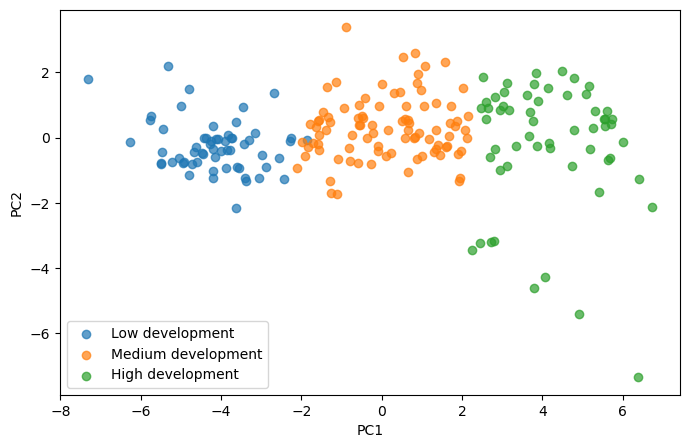

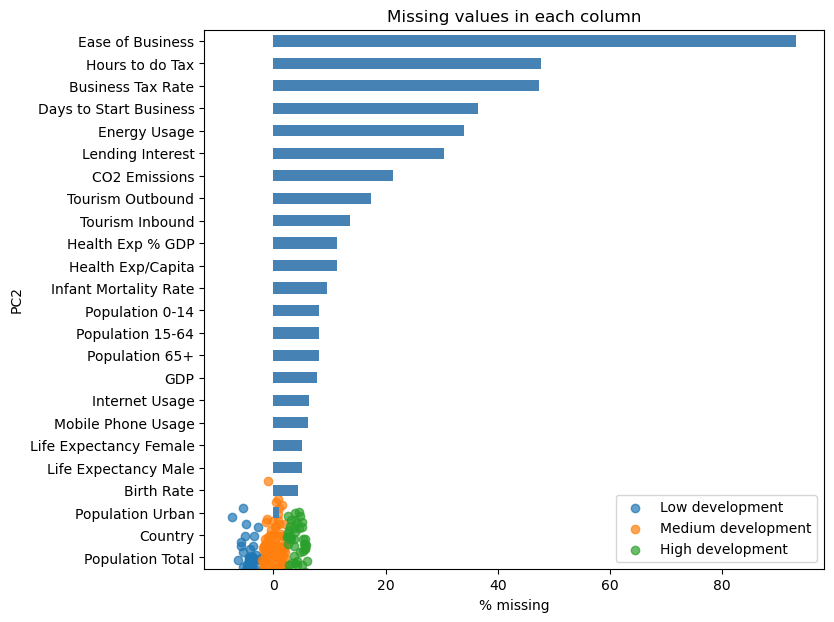

In [63]:
missing_percent.sort_values().plot(kind="barh", figsize=(8, 7), color="steelblue")
plt.xlabel("% missing")
plt.title("Missing values in each column")
plt.show()

**Conclusion:** some columns are mostly empty (for example `Ease of Business` is ~93 % empty) because they were measured in only one or two years. The next step fixes most of this.

## 6. One row per country (aggregation)


In [64]:
country = df.groupby("Country").mean()
print("Shape now:", country.shape)

compare = pd.DataFrame()
compare["before (%)"] = df.drop(columns="Country").isna().mean() * 100
compare["after (%)"] = country.isna().mean() * 100
compare.round(1)

Shape now: (208, 23)


,before (%),after (%)
Birth Rate,4.4,1.0
Business Tax Rate,47.4,11.1
CO2 Emissions,21.4,6.2
Days to Start Business,36.5,11.1
Ease of Business,93.2,11.1
Energy Usage,34.0,19.7
GDP,7.8,5.3
Health Exp % GDP,11.4,11.1
Health Exp/Capita,11.4,11.1
Hours to do Tax,47.6,11.1


**Conclusion:** we now have **208 rows (one per country)** and the missing values dropped from up to 93 % to at most about 22 %. Every column is usable.

## 7. Feature engineering
**Explanation:** big countries have big totals (GDP, CO2, energy, tourism) just because they have many people. That says nothing about development. So we divide by population to get **per-person values**, and we average female and male life expectancy into one column.

Then we remove columns we no longer need: the raw totals, the separate life expectancies, `Population 15-64` (it is just 100 % − young − old) and `Population Total` (size is not development).

In [65]:
data = country.copy()

data["GDP per Capita"] = data["GDP"] / data["Population Total"]
data["CO2 per Capita"] = data["CO2 Emissions"] / data["Population Total"]
data["Energy per Capita"] = data["Energy Usage"] / data["Population Total"]
data["Tourism Inbound per Capita"] = data["Tourism Inbound"] / data["Population Total"]
data["Tourism Outbound per Capita"] = data["Tourism Outbound"] / data["Population Total"]
data["Life Expectancy"] = (data["Life Expectancy Female"] + data["Life Expectancy Male"]) / 2

data = data.drop(columns=["GDP", "CO2 Emissions", "Energy Usage", "Tourism Inbound",
                          "Tourism Outbound", "Life Expectancy Female",
                          "Life Expectancy Male", "Population 15-64", "Population Total"])

features = list(data.columns)
print(len(features), "features used for clustering:")
print(features)
data.describe().T.round(3)

20 features used for clustering:
['Birth Rate', 'Business Tax Rate', 'Days to Start Business', 'Ease of Business', 'Health Exp % GDP', 'Health Exp/Capita', 'Hours to do Tax', 'Infant Mortality Rate', 'Internet Usage', 'Lending Interest', 'Mobile Phone Usage', 'Population 0-14', 'Population 65+', 'Population Urban', 'GDP per Capita', 'CO2 per Capita', 'Energy per Capita', 'Tourism Inbound per Capita', 'Tourism Outbound per Capita', 'Life Expectancy']


,count,mean,std,min,25%,50%,75%,max
Birth Rate,206.0,0.023,0.011,0.008,0.013,0.020,0.029,0.051
Business Tax Rate,185.0,0.484,0.383,0.084,0.331,0.411,0.516,3.074
Days to Start Business,185.0,40.657,57.610,3.000,17.500,27.700,43.200,694.000
Ease of Business,185.0,94.876,54.792,1.000,48.000,94.000,142.000,189.000
Health Exp % GDP,185.0,0.064,0.025,0.021,0.048,0.061,0.080,0.180
Health Exp/Capita,185.0,798.193,1401.445,8.538,52.462,219.385,621.615,6967.385
Hours to do Tax,185.0,299.354,263.396,12.000,155.875,241.000,342.500,2600.000
Infant Mortality Rate,188.0,0.033,0.029,0.002,0.009,0.020,0.054,0.125
Internet Usage,199.0,0.239,0.227,0.000,0.042,0.169,0.385,0.815
Lending Interest,163.0,0.150,0.154,0.018,0.082,0.121,0.181,1.787


**Conclusion:** we have **20 clean features**, all fair to compare between small and large countries.

### 7.1 Distribution of the features (histograms)
**Explanation:** a histogram shows how the values of a feature are spread. Many features have a long tail to the right (a few very rich countries) – this is called **skewness**.

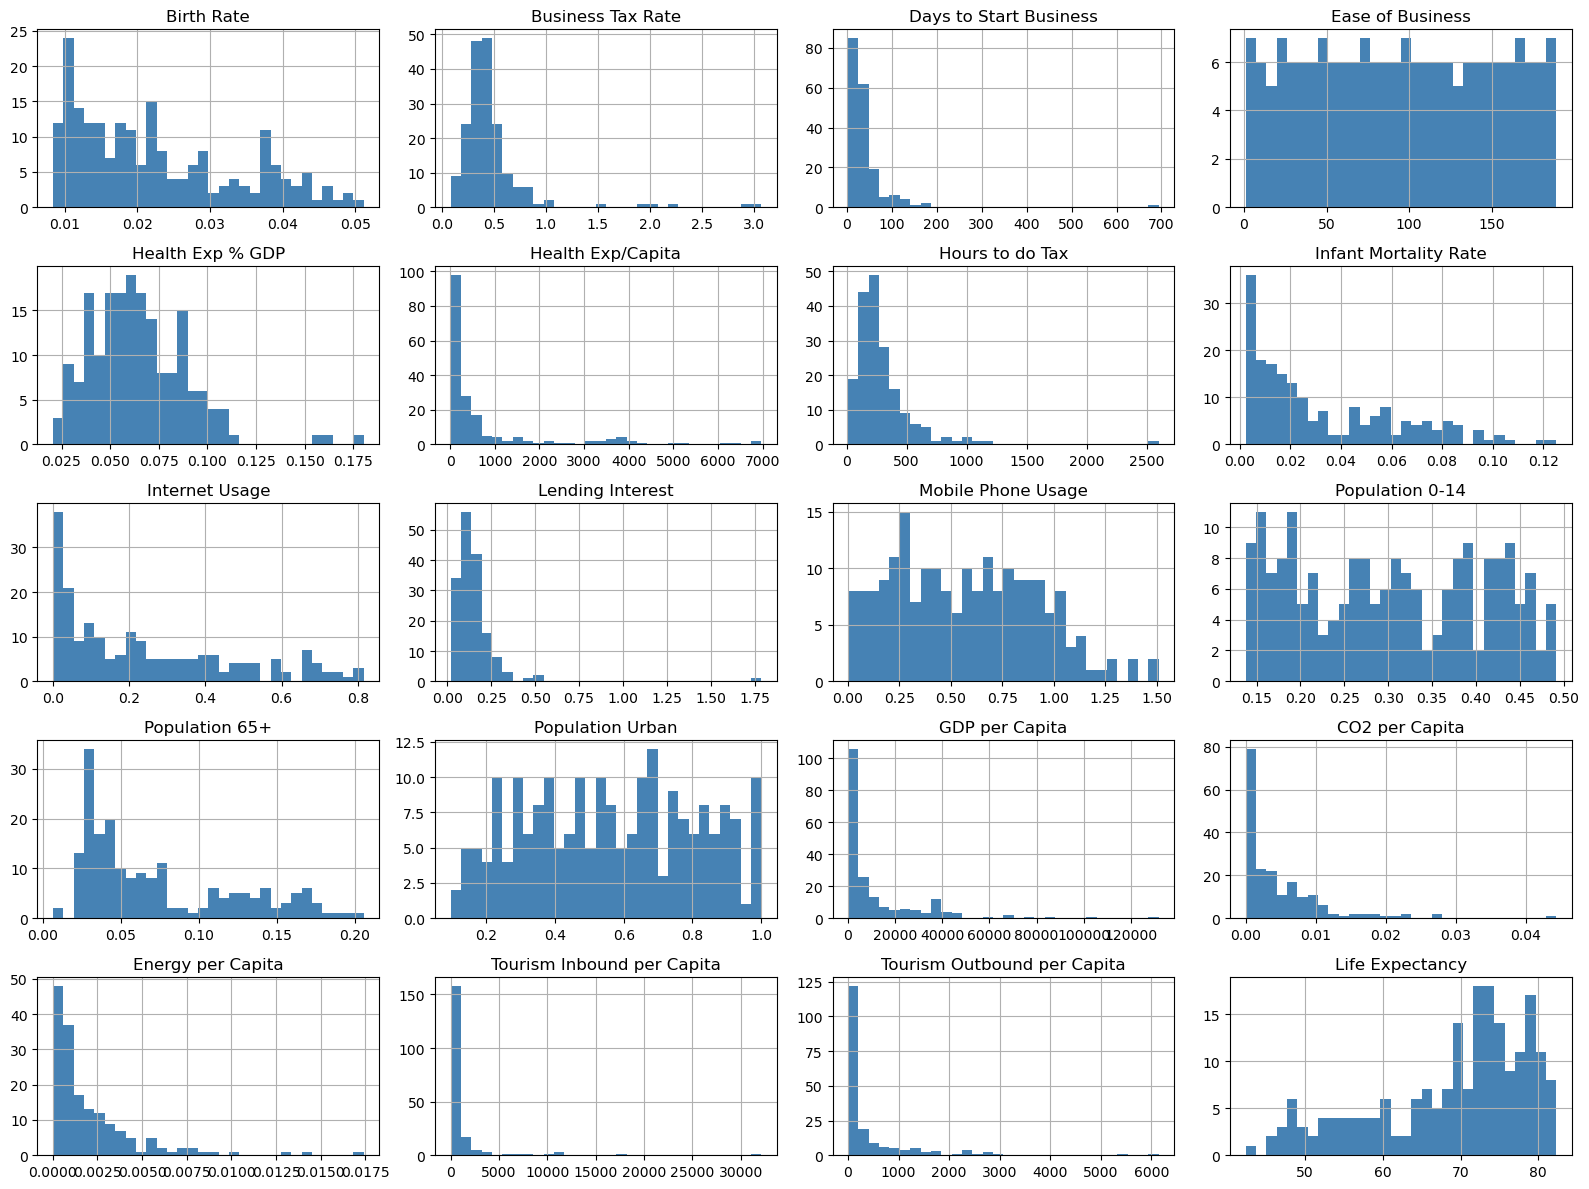

In [66]:
data.hist(bins=30, figsize=(16, 12), color="steelblue")
plt.tight_layout()
plt.show()

**Conclusion:** money-type features (GDP per capita, tourism, CO2, energy) are very skewed. We will fix this in section 8.

### 7.2 Outliers (box plots)
**Explanation:** a box plot shows the middle 50 % of the values as a box; dots outside are *outliers* (unusual countries such as Luxembourg or Qatar).

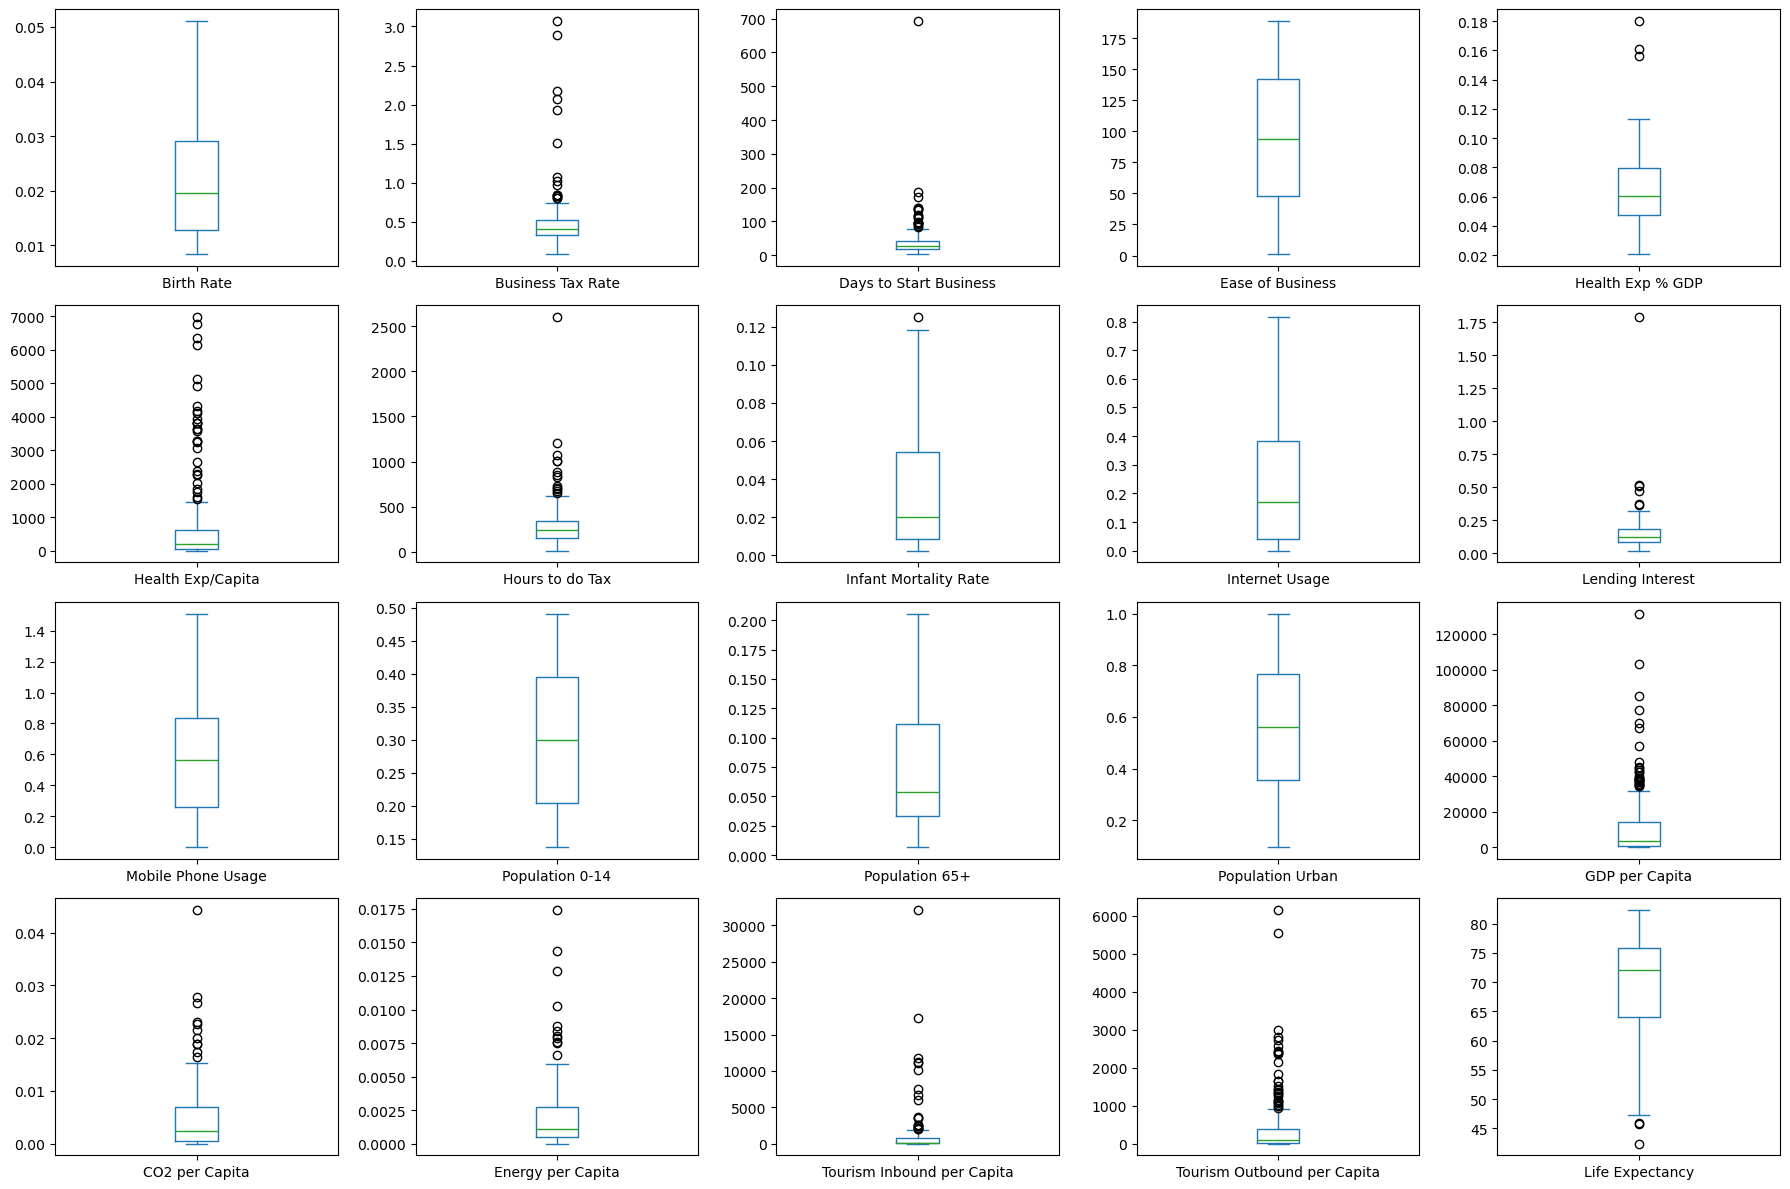

In [67]:
data.plot(kind="box", subplots=True, layout=(4, 5), figsize=(18, 12), sharex=False, sharey=False)
plt.tight_layout()
plt.show()

**Conclusion:** there are many outliers, but they are **real countries**, so we do not delete them. We reduce their effect with a log transform instead.

### 7.3 Correlation heatmap
**Explanation:** correlation (−1 to +1) tells how strongly two features move together. Close to +1 or −1 means they say almost the same thing.

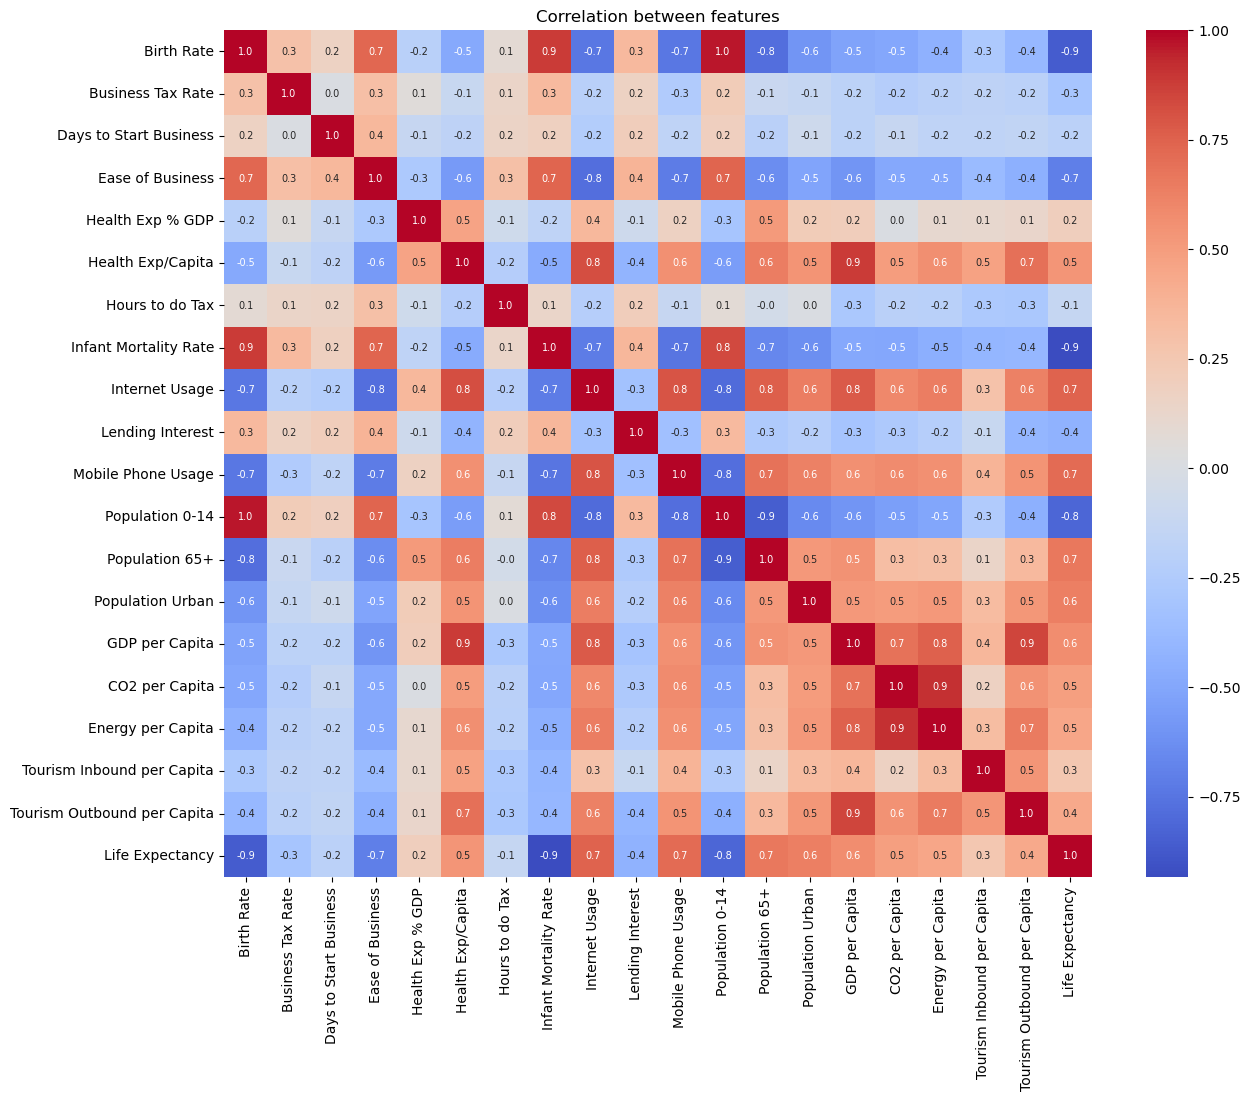

In [68]:
plt.figure(figsize=(14, 11))
sns.heatmap(data.corr(), annot=True, fmt=".1f", cmap="coolwarm", annot_kws={"size": 7})
plt.title("Correlation between features")
plt.show()

**Conclusion:** development indicators are strongly related – for example, higher life expectancy goes with lower infant mortality and lower birth rate. This is why PCA (section 9) is useful.

## 8. Pre-processing (prepare data for the models)
Three simple steps:

**Step 1 – Fill missing values with the median.** The median (middle value) is not disturbed by extreme countries, unlike the average.

**Step 2 – Log transform skewed columns.** `log1p(x)` = log(1 + x). It squeezes long tails so a few giant values do not control the result. We apply it to columns with skewness above 1.

**Step 3 – Scale (standardise).** Clustering measures *distance*. GDP per capita is in thousands but Internet Usage is between 0 and 1, so GDP would dominate. `StandardScaler` puts every feature on the same scale (mean 0, spread 1).

In [69]:
# Step 1: fill missing values
medians = data.median()
data = data.fillna(medians)
print("Missing values left:", data.isna().sum().sum())

Missing values left: 0


Columns transformed: ['Business Tax Rate', 'Days to Start Business', 'Health Exp % GDP', 'Health Exp/Capita', 'Hours to do Tax', 'Infant Mortality Rate', 'Lending Interest', 'Population 65+', 'GDP per Capita', 'CO2 per Capita', 'Energy per Capita', 'Tourism Inbound per Capita', 'Tourism Outbound per Capita']


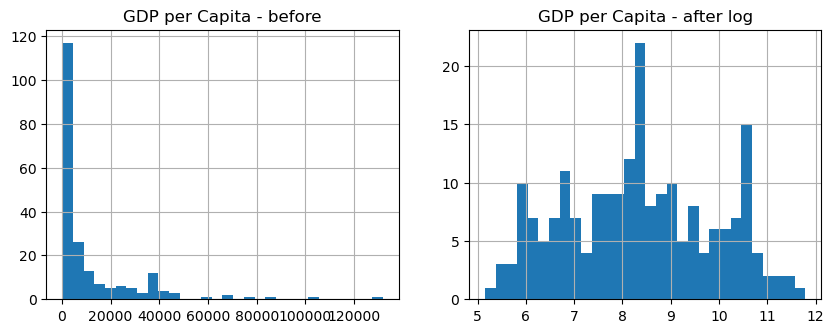

In [70]:
# Step 2: log transform skewed columns
data_log = data.copy()
log_cols = []
for col in features:
    if data[col].skew() > 1 and data[col].min() >= 0:
        log_cols.append(col)

print("Columns transformed:", log_cols)
data_log[log_cols] = np.log1p(data_log[log_cols])

# check one column before and after
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
data["GDP per Capita"].hist(ax=ax[0], bins=30); ax[0].set_title("GDP per Capita - before")
data_log["GDP per Capita"].hist(ax=ax[1], bins=30); ax[1].set_title("GDP per Capita - after log")
plt.show()

In [71]:
# Step 3: scaling
scaler = StandardScaler()
X = scaler.fit_transform(data_log)
print("Shape of X:", X.shape)

Shape of X: (208, 20)


**Conclusion:** `X` (208 countries × 20 features) is clean, has no missing values, is not skewed and every feature is on the same scale. **All models below use this same `X`**, so the comparison is fair.

## 9. PCA (Principal Component Analysis)
**Explanation:** PCA combines many related features into a few new axes called *principal components*. PC1 captures the most information, PC2 the next most, and so on. We use it to (1) see how many dimensions the data really has and (2) **draw the countries on a 2-D chart**.

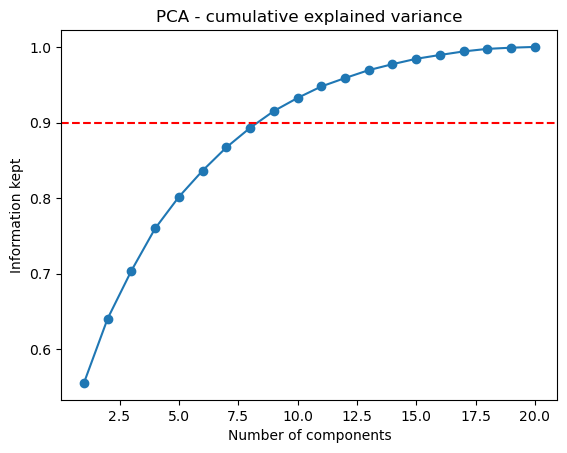

Components needed to keep 90% information: 9
PC1 + PC2 keep: 64.1 %


In [72]:
pca_all = PCA().fit(X)
cumulative = np.cumsum(pca_all.explained_variance_ratio_)

plt.plot(range(1, len(cumulative) + 1), cumulative, marker="o")
plt.axhline(0.90, color="red", linestyle="--")
plt.xlabel("Number of components")
plt.ylabel("Information kept")
plt.title("PCA - cumulative explained variance")
plt.show()

print("Components needed to keep 90% information:", int(np.argmax(cumulative >= 0.90)) + 1)
print("PC1 + PC2 keep:", round(cumulative[1] * 100, 1), "%")

In [73]:
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X)
print("Shape:", X_pca.shape)

Shape: (208, 2)


**Conclusion:** the first two components keep about 64 % of the information – enough to draw a useful picture. About 9 components are needed to keep 90 %. We use PCA mainly for **visualisation**; the models themselves use the full `X`.

## 10. Model 1 – K-Means
**Explanation:** K-Means chooses *k* centre points, gives every country to the nearest centre, moves each centre to the middle of its countries and repeats until nothing changes.

**Problem:** we must choose *k*. Two helpers:
- **Elbow method** – plot *inertia* (how spread out each cluster is). Pick the "elbow" where the line stops dropping quickly.
- **Silhouette score** (−1 to 1) – how well countries fit their own cluster. **Higher is better.**

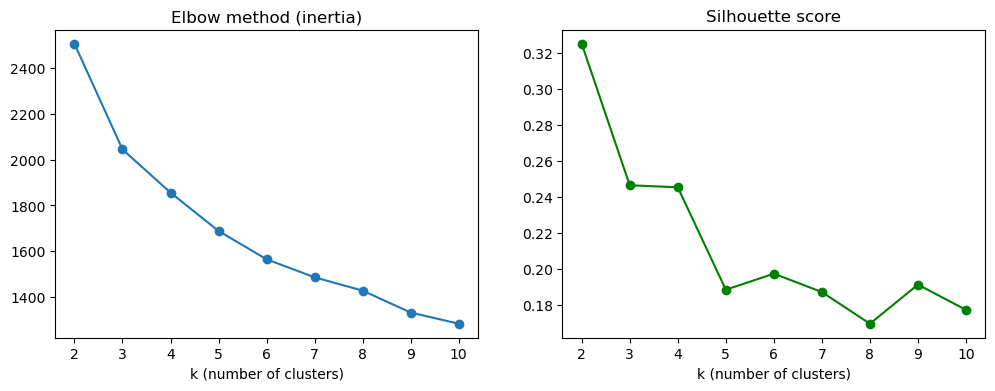

k = 2  silhouette = 0.325
k = 3  silhouette = 0.246
k = 4  silhouette = 0.245
k = 5  silhouette = 0.188
k = 6  silhouette = 0.197
k = 7  silhouette = 0.187
k = 8  silhouette = 0.169
k = 9  silhouette = 0.191
k = 10  silhouette = 0.177


In [74]:
k_values = range(2, 11)
inertia_list = []
silhouette_list = []

for k in k_values:
    model = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = model.fit_predict(X)
    inertia_list.append(model.inertia_)
    silhouette_list.append(silhouette_score(X, labels))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(k_values, inertia_list, marker="o"); ax[0].set_title("Elbow method (inertia)")
ax[1].plot(k_values, silhouette_list, marker="o", color="green"); ax[1].set_title("Silhouette score")
for a in ax:
    a.set_xlabel("k (number of clusters)")
plt.show()

for k, s in zip(k_values, silhouette_list):
    print("k =", k, " silhouette =", round(s, 3))

**How we choose k:** the silhouette is highest for k = 2 (just "developed" vs "developing"), then similar for k = 3 and k = 4, then lower. Scores of about 0.2 – 0.3 mean the groups are **moderately separated** – development is a smooth scale, not sharp boxes. For a business report, 2 groups say too little, so we use **k = 3** (low, medium, high development).

In [75]:
K = 3
kmeans = KMeans(n_clusters=K, n_init=10, random_state=42)
labels_kmeans = kmeans.fit_predict(X)
print("Countries in each cluster:", np.bincount(labels_kmeans))

Countries in each cluster: [57 91 60]


**Conclusion:** K-Means with k = 3 gives three clear-sized groups.

## 11. Model 2 – Hierarchical clustering
**Explanation:** start with every country as its own group, then keep **merging the two closest groups** until one group remains. The merge history drawn as a tree is the **dendrogram**. Cutting the tree at a chosen height gives the clusters. We use *Ward* linkage, which makes compact, similar-sized groups. It needs no random start.

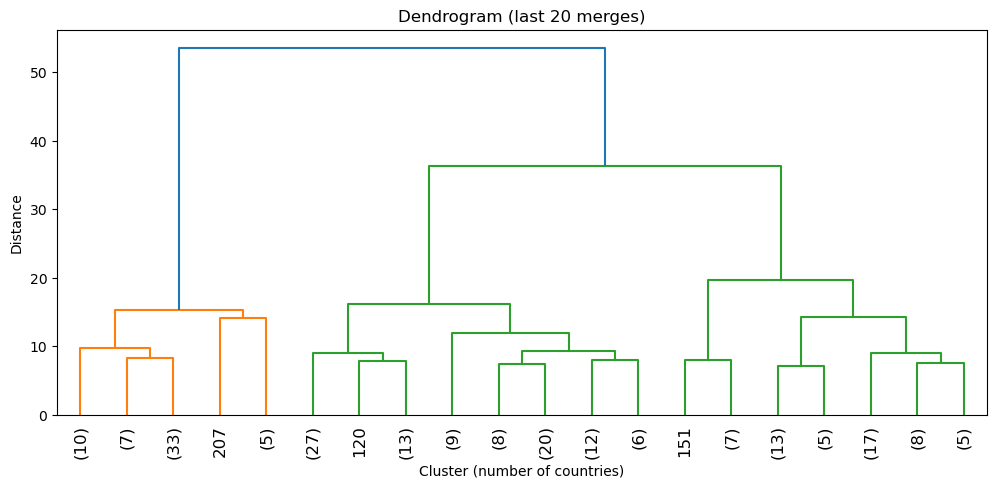

In [76]:
Z = linkage(X, method="ward")
plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode="lastp", p=20, leaf_rotation=90)
plt.title("Dendrogram (last 20 merges)")
plt.xlabel("Cluster (number of countries)")
plt.ylabel("Distance")
plt.show()

In [77]:
hier = AgglomerativeClustering(n_clusters=K, linkage="ward")
labels_hier = hier.fit_predict(X)
print("Countries in each cluster:", np.bincount(labels_hier))

Countries in each cluster: [56 56 96]


**Conclusion:** the big jumps at the top of the dendrogram show 2 – 3 natural groups, which supports using k = 3. The sizes are similar to K-Means.

## 12. Model 3 – DBSCAN
**Explanation:** DBSCAN groups countries that sit in **dense crowded areas** and marks lonely countries as **noise (label −1)**. It does not need k. It has two settings:
- `eps` – how close countries must be to be neighbours
- `min_samples` – how many neighbours make an area "dense"

We try a few `eps` values and see what happens.

In [78]:
for eps in [2.0, 2.5, 2.75, 3.0, 4.0]:
    labels = DBSCAN(eps=eps, min_samples=3).fit_predict(X)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = list(labels).count(-1)
    print("eps =", eps, "| clusters =", n_clusters, "| noise countries =", n_noise)

eps = 2.0 | clusters = 5 | noise countries = 114
eps = 2.5 | clusters = 1 | noise countries = 50
eps = 2.75 | clusters = 2 | noise countries = 29
eps = 3.0 | clusters = 1 | noise countries = 16
eps = 4.0 | clusters = 1 | noise countries = 4


In [79]:
dbscan = DBSCAN(eps=2.75, min_samples=3)
labels_dbscan = dbscan.fit_predict(X)
print("Labels and number of countries (-1 = noise):")
print(pd.Series(labels_dbscan).value_counts())

Labels and number of countries (-1 = noise):
 0    175
-1     29
 1      4
Name: count, dtype: int64


**Conclusion:** DBSCAN does not work well here.
- With a small `eps` (2.0) more than half of the countries (114 of 208) are labelled noise.
- With a larger `eps` (2.5, 3.0, 4.0) everything merges into **one** big group.
- The only setting that gives 2 groups (`eps = 2.75`) produces one group of 175 countries, one tiny group of 4, and 29 noise countries.

The reason is that countries form a **continuous spread** rather than separate crowded islands, so DBSCAN cannot split them in a useful way. It is not suitable for segmenting this dataset.

## 13. Model 4 – Gaussian Mixture Model (GMM)
**Explanation:** GMM assumes each cluster is a bell-shaped cloud of countries. Unlike K-Means, it gives each country a **probability** of belonging to every cluster. We choose the number of clusters with **BIC** (lower is better; it rewards a good fit but punishes too much complexity).

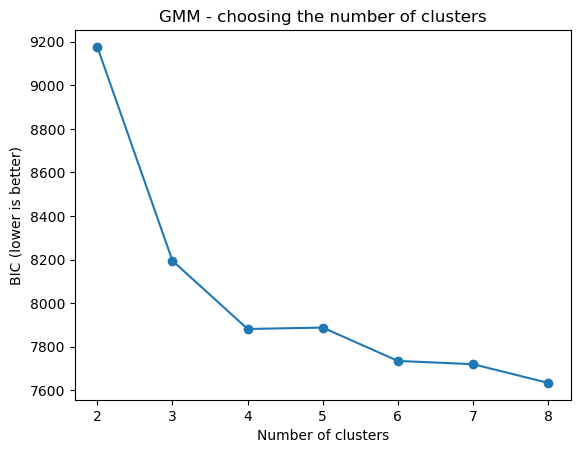

In [80]:
bic_values = []
for k in range(2, 9):
    gmm_test = GaussianMixture(n_components=k, covariance_type="diag", random_state=42)
    gmm_test.fit(X)
    bic_values.append(gmm_test.bic(X))

plt.plot(range(2, 9), bic_values, marker="o")
plt.xlabel("Number of clusters"); plt.ylabel("BIC (lower is better)")
plt.title("GMM - choosing the number of clusters")
plt.show()

In [81]:
gmm = GaussianMixture(n_components=K, covariance_type="diag", random_state=42)
labels_gmm = gmm.fit_predict(X)
print("Countries in each cluster:", np.bincount(labels_gmm))

Countries in each cluster: [56 80 72]


**Conclusion:** GMM with 3 clusters works, with results close to K-Means. (We use `diag` covariance because 208 countries are too few for the full version.)

## 14. Compare all models
**Explanation:** we have no "correct answers", so we use three scores that judge the clusters themselves:

| Score | Meaning | Better is |
|---|---|---|
| Silhouette | countries are close to own cluster, far from others | **higher** |
| Davies-Bouldin | clusters are not overlapping | **lower** |
| Calinski-Harabasz | clusters are compact and far apart | **higher** |

For DBSCAN we ignore the noise countries when scoring.

In [82]:
all_labels = {"K-Means": labels_kmeans,
              "Hierarchical": labels_hier,
              "DBSCAN": labels_dbscan,
              "GMM": labels_gmm}

rows = []
for name in all_labels:
    labels = all_labels[name]
    keep = labels != -1                       # remove noise points
    rows.append([name,
                 len(set(labels[keep])),
                 int((~keep).sum()),
                 silhouette_score(X[keep], labels[keep]),
                 davies_bouldin_score(X[keep], labels[keep]),
                 calinski_harabasz_score(X[keep], labels[keep])])

results = pd.DataFrame(rows, columns=["Model", "Clusters", "Noise countries",
                                      "Silhouette (high)", "Davies-Bouldin (low)",
                                      "Calinski-Harabasz (high)"])
results.round(3)

,Model,Clusters,Noise countries,Silhouette (high),Davies-Bouldin (low),Calinski-Harabasz (high)
0,K-Means,3,0,0.246,1.353,106.008
1,Hierarchical,3,0,0.245,1.341,103.570
2,DBSCAN,2,29,0.237,0.969,8.332
3,GMM,3,0,0.228,1.393,102.747


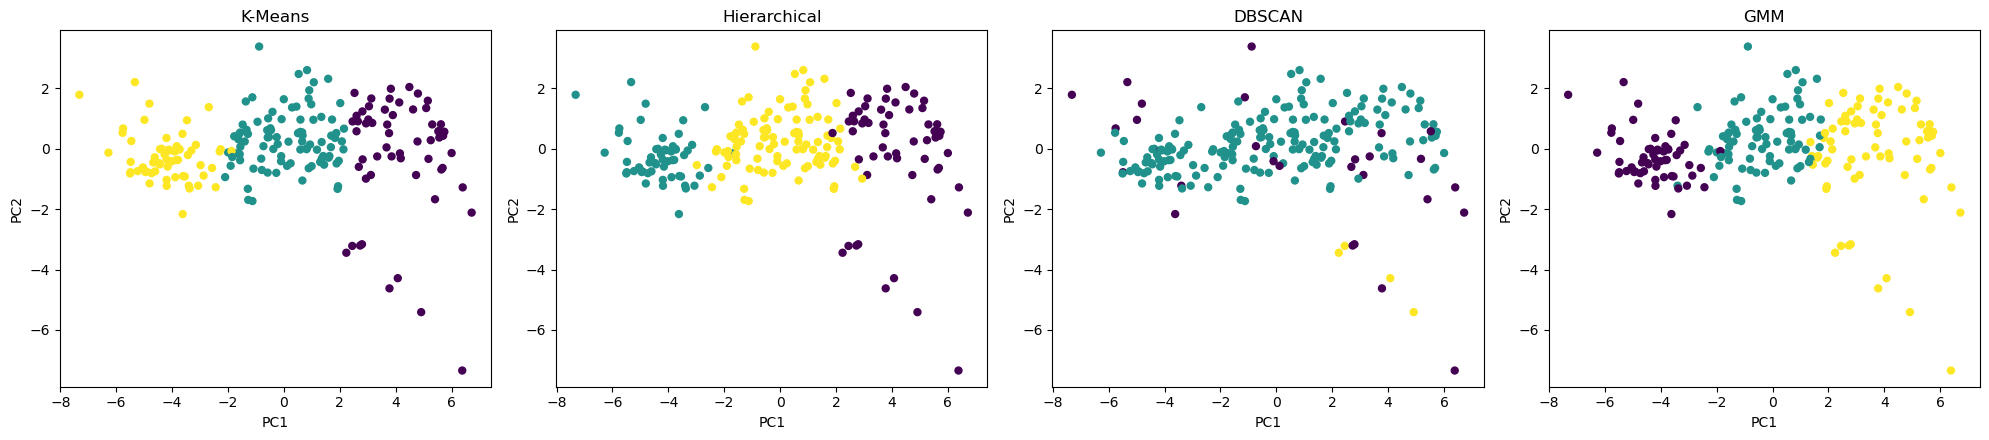

In [83]:
# draw all four models on the PCA chart
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, name in zip(axes, all_labels):
    ax.scatter(X_pca[:, 0], X_pca[:, 1], c=all_labels[name], cmap="viridis", s=25)
    ax.set_title(name)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
plt.tight_layout()
plt.show()

### 🏆 Conclusion – which model is best?
- **K-Means** has the best Silhouette and Calinski-Harabasz scores among the models that use 3 clusters, it puts **every** country into a cluster, and it is simple to explain and deploy.
- **Hierarchical** and **GMM** are very close behind (Hierarchical is even slightly better on Davies-Bouldin, 1.34 vs 1.35). The scores are so close that different methods agree – this shows the result is stable.
- **DBSCAN** may show a good Davies-Bouldin number, but that is misleading: it leaves countries as noise and its groups are not useful.

**➜ We choose K-Means as the final model.**

## 15. Understand the clusters (profiling)
**Explanation:** a cluster is only useful if we can **describe** it. We add the cluster number to each country, then look at the typical (median) value of each feature in each cluster. We also name the clusters by their life expectancy: lowest life expectancy = "Low development", and so on.

In [84]:
result = data.copy()                      # values in original units
result["Cluster"] = labels_kmeans
result["PC1"] = X_pca[:, 0]
result["PC2"] = X_pca[:, 1]

# order clusters from lowest to highest life expectancy
order = result.groupby("Cluster")["Life Expectancy"].median().sort_values().index.tolist()
names = ["Low development", "Medium development", "High development"]

cluster_names = {}
for i in range(len(order)):
    cluster_names[order[i]] = names[i]

result["Cluster Name"] = result["Cluster"].map(cluster_names)
print(cluster_names)
result["Cluster Name"].value_counts()

{2: 'Low development', 1: 'Medium development', 0: 'High development'}


Cluster Name
Medium development    91
Low development       60
High development      57
Name: count, dtype: int64

In [85]:
profile = result.groupby("Cluster Name")[features].median()
profile = profile.loc[names]
profile.T.round(3)

Cluster Name,Low development,Medium development,High development
Birth Rate,0.038,0.019,0.012
Business Tax Rate,0.429,0.411,0.410
Days to Start Business,39.600,27.700,20.300
Ease of Business,155.000,94.000,35.000
Health Exp % GDP,0.056,0.061,0.072
Health Exp/Capita,32.692,219.385,1433.923
Hours to do Tax,266.000,241.000,170.000
Infant Mortality Rate,0.067,0.020,0.005
Internet Usage,0.020,0.169,0.492
Lending Interest,0.158,0.121,0.076


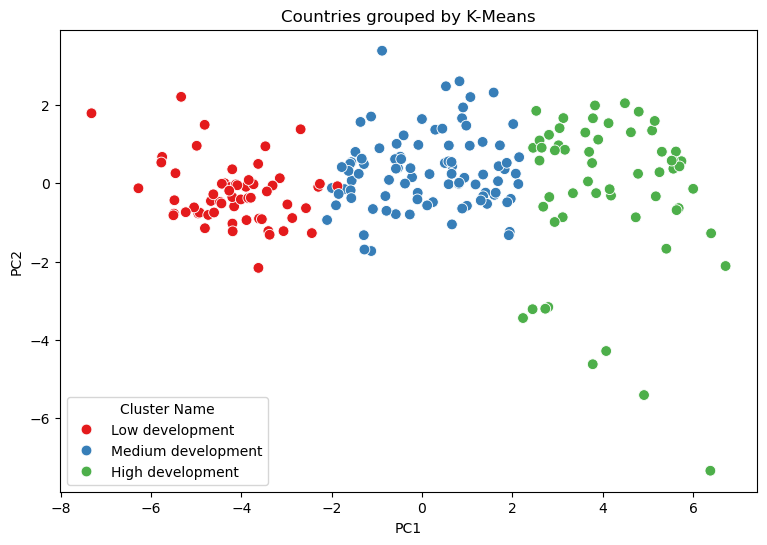

In [86]:
# chart of all countries coloured by cluster
plt.figure(figsize=(9, 6))
sns.scatterplot(data=result, x="PC1", y="PC2", hue="Cluster Name", hue_order=names, palette="Set1", s=60)
plt.title("Countries grouped by K-Means")
plt.show()

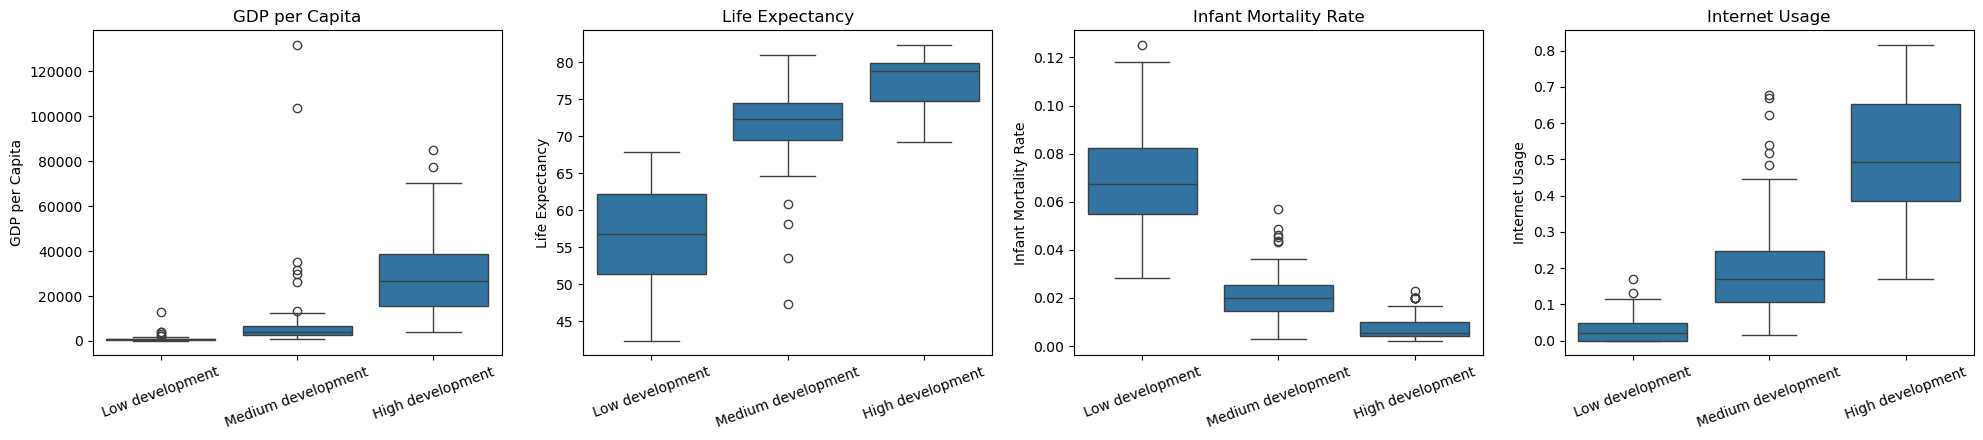

In [87]:
# compare main indicators
main = ["GDP per Capita", "Life Expectancy", "Infant Mortality Rate", "Internet Usage"]
fig, axes = plt.subplots(1, 4, figsize=(20, 4.5))
for ax, col in zip(axes, main):
    sns.boxplot(data=result, x="Cluster Name", y=col, order=names, ax=ax)
    ax.set_title(col); ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 16. Save the model for deployment
**Explanation:** a new country must go through the **same steps** as our data: fill missing → log → scale → K-Means. So we save everything needed in one file with `joblib`, and the result table as a CSV for the app.

In [88]:
model_info = {"features": features,
              "log_cols": log_cols,
              "medians": medians.to_dict(),
              "scaler": scaler,
              "model": kmeans,
              "cluster_names": cluster_names}

joblib.dump(model_info, "cluster_artifacts.joblib")
result.reset_index().to_csv("country_clusters.csv", index=False)
print("Saved: cluster_artifacts.joblib and country_clusters.csv")

Saved: cluster_artifacts.joblib and country_clusters.csv


In [89]:
saved = joblib.load("cluster_artifacts.joblib")

new_country = data.loc[["India"], features].copy()                     # raw numbers of India
new_country[saved["log_cols"]] = np.log1p(new_country[saved["log_cols"]])   # log
new_scaled = saved["scaler"].transform(new_country)                    # scale
label = saved["model"].predict(new_scaled)[0]                          # predict

print("App prediction  :", saved["cluster_names"][label])
print("Notebook result :", result.loc["India", "Cluster Name"])

App prediction  : Low development
Notebook result : Low development


## 17. Deployment with Streamlit
**Explanation:** Streamlit turns a Python file into a website – no HTML needed. The cell below creates `app.py` with 3 tabs:
1. **Cluster map** – chart of all countries coloured by cluster
2. **Country lookup** – choose a country, see its cluster and neighbours
3. **Predict new country** – move sliders, get the predicted cluster


In [90]:
%pip install streamlit pandas numpy scikit-learn matplotlib joblib openpyxl

Note: you may need to restart the kernel to use updated packages.


In [91]:
import joblib

joblib.dump(kmeans, "cluster_model.pkl")

print("Model saved successfully")

Model saved successfully


In [92]:
joblib.dump(scaler, "scaler.pkl")

['scaler.pkl']

In [93]:
%%writefile requirements.txt
streamlit
pandas
numpy
scikit-learn
matplotlib
joblib
openpyxl

Overwriting requirements.txt


In [96]:
%%writefile app.py
# Streamlit app - run with:  streamlit run app.py
import joblib
import numpy as np
import pandas as pd
import streamlit as st
import matplotlib.pyplot as plt

st.title("Global Development - Country Clusters")

# load the files created by the notebook
model_info = joblib.load("cluster_artifacts.joblib")
data = pd.read_csv("country_clusters.csv")
features = model_info["features"]

tab1, tab2, tab3 = st.tabs(["Cluster map", "Country lookup", "Predict new country"])

# ---- Tab 1: scatter plot of all countries
with tab1:
    fig, ax = plt.subplots(figsize=(8, 5))
    for name in data["Cluster Name"].unique():
        part = data[data["Cluster Name"] == name]
        ax.scatter(part["PC1"], part["PC2"], label=name, alpha=0.7)
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend()
    st.pyplot(fig)
    st.write("Countries in each cluster")
    st.write(data["Cluster Name"].value_counts())

# ---- Tab 2: look up one country
with tab2:
    country = st.selectbox("Choose a country", sorted(data["Country"]))
    row = data[data["Country"] == country].iloc[0]
    st.subheader(country + " belongs to: " + row["Cluster Name"])
    same = data[data["Cluster Name"] == row["Cluster Name"]]
    st.write("Other countries in this cluster:", ", ".join(same["Country"]))
    st.write("Average of the cluster:")
    st.write(same[features].mean())

# ---- Tab 3: classify a new country
with tab3:
    st.write("Move the sliders. All other indicators use the world median.")
    values = dict(model_info["medians"])
    for f in ["GDP per Capita", "Life Expectancy", "Infant Mortality Rate",
              "Birth Rate", "Internet Usage"]:
        low = float(data[f].min())
        high = float(data[f].max())
        values[f] = st.slider(f, low, high, float(model_info["medians"][f]))
    if st.button("Predict cluster"):
        x = pd.DataFrame([values])[features]
        x[model_info["log_cols"]] = np.log1p(x[model_info["log_cols"]])
        x_scaled = model_info["scaler"].transform(x)
        label = model_info["model"].predict(x_scaled)[0]
        st.success("Predicted cluster: " + model_info["cluster_names"][label])

Overwriting app.py


In [97]:
import os

print(os.getcwd())
print(os.path.exists("app.py"))

C:\Users\sirip
True


## 18. Final conclusion

| Step | What we did | Why |
|---|---|---|
| Cleaning | converted `$` and `%` text into numbers | models need numbers |
| Aggregation | 2,704 rows → 208 countries | cluster countries, not country-years; fewer missing values |
| Feature engineering | per-capita values, average life expectancy | remove the country-size effect |
| EDA | histograms, box plots, correlation | find skewness, outliers, related features |
| Pre-processing | median fill, log, scaling | fair distances, outliers under control |
| PCA | reduced to 2 axes | to draw the clusters |
| Models | K-Means, Hierarchical, DBSCAN, GMM | comparative analysis (project requirement) |
| Evaluation | Silhouette, Davies-Bouldin, Calinski-Harabasz | judge clusters without labels |
| Deployment | joblib + Streamlit | project requirement |

**Main result:** K-Means with **3 clusters** (low, medium, high development) is the best and simplest model for this dataset. Hierarchical and GMM agree with it; DBSCAN is not suitable.

**Limitations and ideas**
- Years are not labelled, so we cannot see how countries *change* over time.
- Cluster separation is moderate because development is a continuous scale.
- Try other values of `K` (2 to 5) or a smarter missing-value method such as `KNNImputer`.